POE Task 2 : Classification and model improvement
Rebaabetswe Kotu
ST10547119

This project aims to optimise and automate the detection of malignant breast tumors by distinguishing them from benign breast tumors using the Breast Cancer Wisconsin Diagnostic dataset. The project showcases how classification model can be used for accurate differentiation and further be improved if required.

In [21]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
   accuracy_score, precision_score, recall_score, f1_score,
   roc_auc_score, confusion_matrix, classification_report,
   ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
print("Libraries loaded successfully")

Libraries loaded successfully


1. Loading the dataset

In [22]:
data = pd.read_csv("Book1.xlsx Breast cancer dataset.csv")

feature_names = [
    "mean radius", "mean texture", "mean perimeter", "mean area",
    "mean smoothness", "mean compactness", "mean concavity",
    "mean concave points", "mean symmetry", "mean fractal dimensions",
    "radius error", "texture error", "perimeter error", "area error",
    "smoothness error", "compactness error", "concavity error",
    "concave points error", "symmetry error", "fractal dimension error",
    "worst radius", "worst texture", "worst perimeter", "worst area",
    "worst smoothness", "worst compactness", "worst concavity",
    "worst concave points", "worst symmetry", "worst fractal dimension"
]
data.columns = ["id", "diagnosis"] + feature_names

print("Dataset shape:", data.shape)
display(data.head())
print("\Column data types:")
display(data.dtypes.value_counts().rename_axis("data type").to_frame("count"))
print("\nDiagnosis counts:")
display(data["diagnosis"].value_counts().rename(index={"B": "Benign", "M": "Malignant"}))

Dataset shape: (569, 32)


,id,diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimensions,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


\Column data types:


,count
data type,
float64,30
int64,1
str,1



Diagnosis counts:


diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

The dataset is made up of 569 rows of patient's samples and 32 columns. The first two columns are ID and the diagnosis, which is either malignant or benign and the other 30 columns are measurements of a cell nucleus image obtained from a breast tumor. The columns are labeled as column 1 to 32 on the provided dataset, we've now used feature names to re-label the columns. 357 of the samples are benign, while 212 samples are malignant.

2. Data quality checks: Duplicates and missing values

In [23]:

print("Missing cells:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))
print("Duplicate IDs:", int(data["id"].duplicated().sum()))
print("\nDiagnosis labels:", sorted(data["diagnosis"].dropna().unique()))

data = data.dropna(subset=["diagnosis"]).copy()

X = data.drop(columns=["id", "diagnosis"])
y = (data["diagnosis"] == "M").astype(int)

print("Predictor matrix:", X.shape)
print("Target counts (0=benign, 1=malignant):")
display(y.value_counts().sort_index().rename(index={0: "Benign (0)", 1: "Malignant (1)"}))

Missing cells: 0
Duplicate rows: 0
Duplicate IDs: 0

Diagnosis labels: ['B', 'M']
Predictor matrix: (569, 30)
Target counts (0=benign, 1=malignant):


diagnosis
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64

The dataset has no missing values and no duplicates, imputation is therefore not required. Benign tumors account for about 37% of the dataset, while malignant tumors account for about 62% of the dataset, this demonstrates a mild class imbalance. However, for a medical dataset, the distribution is relatively healthy.

3. Explaratory data analysis

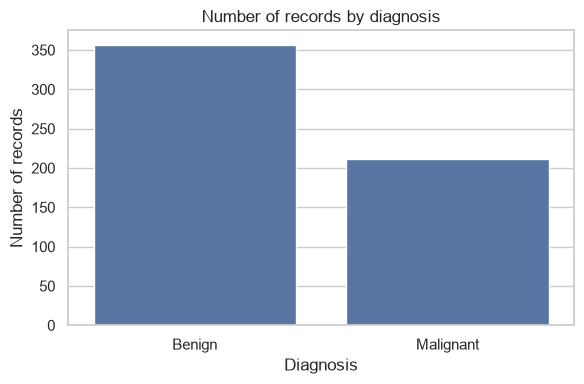

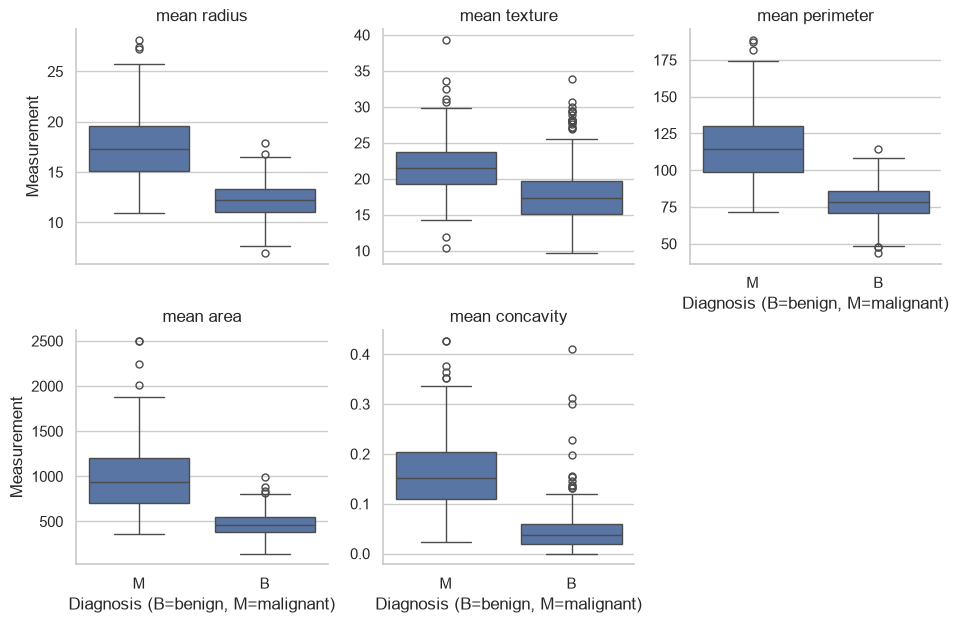

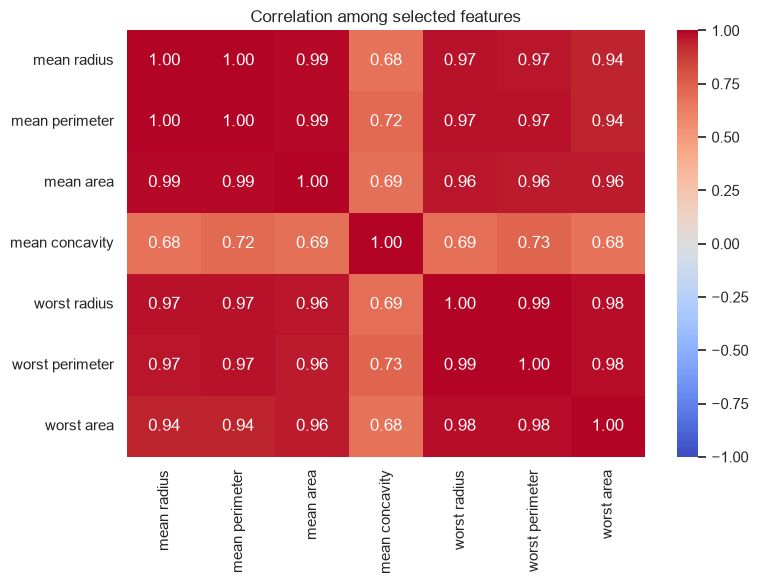

In [24]:
counts = data["diagnosis"].value_counts().reindex(["B", "M"])
plt.figure(figsize=(6, 4))
sns.barplot(x=["Benign", "Malignant"], y=counts.values)
plt.title("Number of records by diagnosis")
plt.ylabel("Number of records")
plt.xlabel("Diagnosis")
plt.tight_layout()
plt.show()

eda_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean concavity"]
long_data = data.melt(id_vars="diagnosis", value_vars=eda_features,
                      var_name="Feature", value_name="Measurement")
g = sns.catplot(data=long_data, x="diagnosis", y="Measurement", col="Feature",
               kind="box", col_wrap=3, sharey=False, height=3.2)
g.set_titles("{col_name}")
g.set_axis_labels("Diagnosis (B=benign, M=malignant)", "Measurement")
plt.show()

corr_features = ["mean radius", "mean perimeter", "mean area", "mean concavity", "worst radius", "worst perimeter", "worst area"]

plt.figure(figsize=(8, 6))
sns.heatmap(data[corr_features].corr(),annot=True, cmap="coolwarm", fmt=".2f",
vmin=-1, vmax=1)
plt.title("Correlation among selected features")
plt.tight_layout()
plt.show()

EDA interpretation:

Although there is an imbalance in the diagnosis distribution, it is not a case of a severely imbalanced class. This allows for the classification model to be safely trained using standard stratified splits. The boxplots demonstrate different patterns across all physical traits. The mean radius, area and perimeter benign boxplot sit significantly lower on the scale, while the malignant boxplots are higher. That is because malignant cells divide rapidly, and as a result, they are larger in size. Cell nuclie size is important because the measurements are strong predictors. The mean texture and concavity benign boxplots also sit below the malignant boxplots because of the abnormality of cells when they are malignant. Their texture is darker with irregular edges, both texture and concavity makes it easier to separate malignant cells from benign cells. The heatmap demonstrate strong positive correlations between features of the worst column and a corresponding mean column. This is indicative of tumor progression.

4. Train test split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "Benign", 1: "Malignant"}))
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0: "Benign", 1: "Malignant"}))

Training records: 455
Test records: 114

Training target proportions:


diagnosis
Benign       0.626374
Malignant    0.373626
Name: proportion, dtype: float64


Test target proportions:


diagnosis
Benign       0.631579
Malignant    0.368421
Name: proportion, dtype: float64

The dataset is split into 80/20 split, yielding 455 training records and 114 testing records. The proportions are similar between both the training and test target, benign diagnosis accounts for about 63% while malignant diagnosis accounts for about 37%. This serves as a confirmation that during the split, stratification was correctly applied.

5. Feature and model selection, hypertuning

In [26]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif)),
    ("model", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "select__k": [10, 15, 20, 30],
    "model__C": [0.01, 0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best mean cross-validation malignant recall:", round(search.best_score_, 4))
best_model = search.best_estimator_

selected_features = X.columns[best_model.named_steps["select"].get_support()].tolist()
print("\nSelected features ({}):".format(len(selected_features)))
print(selected_features)

Best parameters: {'model__C': 1, 'select__k': 30}
Best mean cross-validation malignant recall: 0.9588

Selected features (30):
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimensions', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


The target variable has binary outcome and logistic regression is therefore a suitable baseline for classification. It is easy to interpret.

Feature selection: The feature select algorithm did not drop any features, it retained all 30 of them, k=30. This gives the model an advantage to make accurate cancer diagnosis.

Hyperparameter tuning: C is standardized and kept at C:1. This acts as a safety net to prevent over and underfitting. At C=1, the regulisation shrinks coefficients of metrics considered to be unnecessary among the 30 features to keep the model stable.

Metric evaluation: A recall of 95.88% is outstanding, this means that for every 100 malignat tumors, the model is able to successfully catch 96 and only misses 4 during cross validation. This shows that the model is highly sensitive, which is important for a diagnostic support tool.

6. Final evaluation metrics

,Metric,Score
0,Accuracy,0.9737
1,Precision (malignant),0.9756
2,Recall / sensitivity (malignant),0.9524
3,F1-score (malignant),0.9639
4,ROC-AUC,0.9954


Confusion matrix (rows=actual, columns=predicted; order: benign, malignant):
[[71  1]
 [ 2 40]]

Classification report:
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



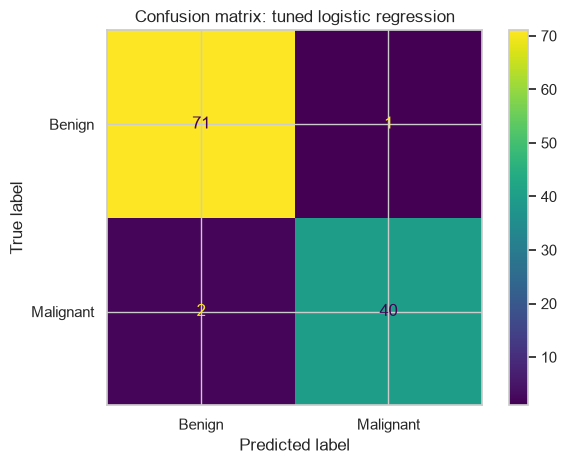

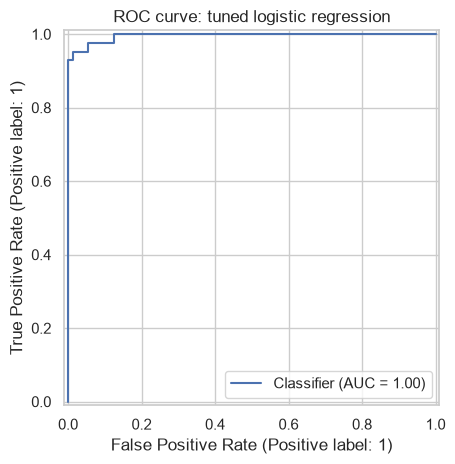

In [27]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (malignant)": precision_score(y_test, y_pred, zero_division=0),
    "Recall / sensitivity (malignant)": recall_score(y_test, y_pred, zero_division=0),
    "F1-score (malignant)": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}
metrics_table = pd.DataFrame({"Metric": list (metrics.keys()),
                              "Score": [round(v, 4) for v in metrics.values()]})
display(metrics_table)

cm=confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows=actual, columns=predicted; order: benign, malignant):")
print(cm)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"], zero_division=0))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Malignant"]).plot()
plt.title("Confusion matrix: tuned logistic regression")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve: tuned logistic regression")
plt.tight_layout()
plt.show()

The above obtained results show that the model is clinically safe, stable and accurate.

The model managed to correctly classify 111 records out of 114 testing records, resulting in a final accuracy of 97.37%. The final test set yielded a malignant recall of 95.24% which is almost the same as the 95.88% malignant recall obtained during cross validation, this means that the model is not overfitting. Regulisation strategy of C=1 was a good choice. However, the model still has some errors which we see on the confusion matrix. The model managed to correctly identify 40 malignant tumors and 71 benign tumors. There's only 2 false negatives and only 1 false positive, these are not ideal but manageable numbers. A malignant precision of 97.56% shows that 97.56% of the time a tumor is classified as malignant, it is a correct classification and 95.24% malignant recall means the model is able to catch over 95% malignant tumors. F1-score of 0.96 demonstrate that both recall and precision performed well. ROC- AUC of 0.9954 is almost perfect, this means the model is able to differentiate between benign and malignant very well.

Conclusion

To get a full picture of a model's performance in classification, all metrics must be evaluated. A well balanced dataset is important because it determines which evaluation tool is suitable. EDA and data inspection cannot therefore be excluded from the processes. The project demonstrated a successful development and evaluation of a machine learning pipeline, for classification of binary tumor outcome.